In [1]:
!pip install shap lime captum scipy matplotlib


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=dfed0503cd1434863cb241ed5746644ff2e37a7a59a349399838b15dde4ac4ce
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [captum]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import shap

from lime.lime_tabular import LimeTabularExplainer
from captum.attr import Saliency
from scipy.stats import spearmanr

In [3]:
def mask_eeg(x, mask):
    """
    x : EEG de forme (16, 10, 200)
    mask : matrice (16, 10)
           1 = conserver
           0 = masquer
    """
    return x * mask[:, :, None]

In [4]:
def top_k_mask(importance, percentage=0.2):
    """
    importance : matrice (16, 10)
    percentage : proportion à masquer
    """
    scores = np.abs(importance).flatten()
    k = max(1, int(len(scores) * percentage))

    indices = np.argsort(scores)[-k:]

    mask = np.ones(len(scores))
    mask[indices] = 0

    return mask.reshape(16, 10)

In [5]:
def robustness_score(original, perturbed):
    a = np.abs(original).flatten()
    b = np.abs(perturbed).flatten()

    corr, _ = spearmanr(a, b)
    return corr

In [6]:
# Créer un faux signal EEG pour tester les fonctions
np.random.seed(42)

x = np.random.randn(16, 10, 200)
importance = np.random.rand(16, 10)

# Masquer les 20 % de zones les plus importantes
mask = top_k_mask(importance, percentage=0.2)
x_masked = mask_eeg(x, mask)

# Vérifier les dimensions et le masquage
print("EEG original :", x.shape)
print("EEG masqué :", x_masked.shape)
print("Nombre de zones masquées :", np.sum(mask == 0))

# Tester la stabilité avec deux cartes identiques
score = robustness_score(importance, importance)
print("Robustness :", score)

EEG original : (16, 10, 200)
EEG masqué : (16, 10, 200)
Nombre de zones masquées : 32
Robustness : 1.0


In [7]:
def plot_importance(importance, title="EEG XAI Importance"):
    plt.figure(figsize=(12, 6))

    plt.imshow(
        importance,
        aspect="auto",
        cmap="coolwarm",
        interpolation="nearest"
    )

    plt.colorbar(label="Importance")
    plt.xlabel("Time (seconds)")
    plt.ylabel("EEG channels")
    plt.xticks(range(10), range(1, 11))
    plt.yticks(range(16), range(1, 17))
    plt.title(title)
    plt.tight_layout()
    plt.show()

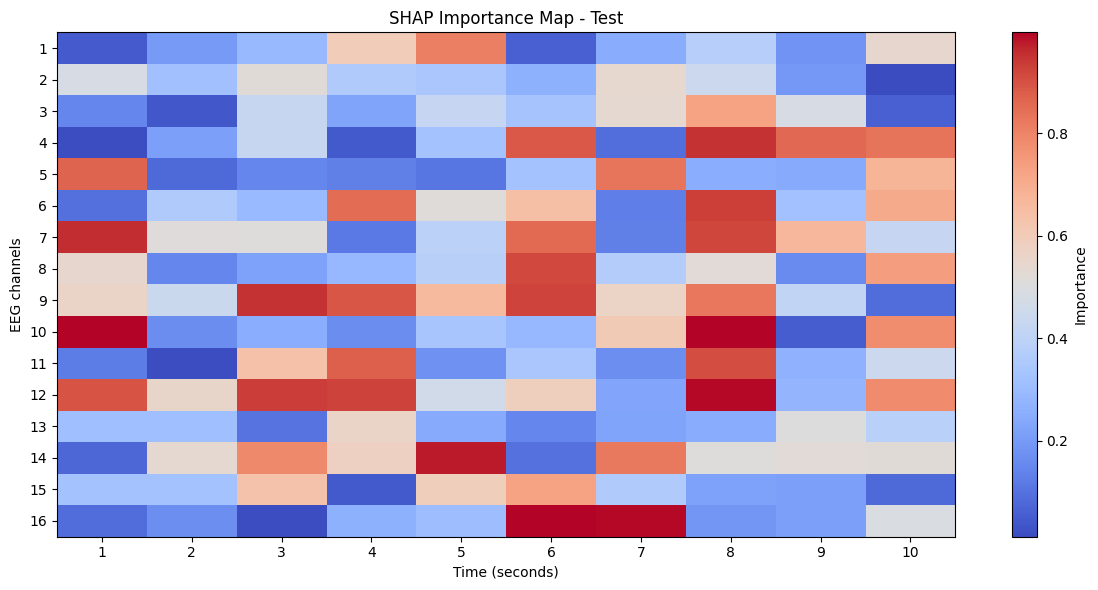

In [8]:
plot_importance(
    importance,
    title="SHAP Importance Map - Test"
)

In [9]:
def compare_xai(shap_values, lime_values, saliency_values):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    methods = [
        ("SHAP", shap_values),
        ("LIME", lime_values),
        ("Saliency", saliency_values)
    ]

    for ax, (name, values) in zip(axes, methods):
        im = ax.imshow(
            np.abs(values),
            aspect="auto",
            cmap="viridis",
            interpolation="nearest"
        )

        ax.set_title(name)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("EEG channels")
        ax.set_xticks(range(10))
        ax.set_xticklabels(range(1, 11))

        fig.colorbar(im, ax=ax, label="Absolute importance")

    plt.tight_layout()
    plt.show()

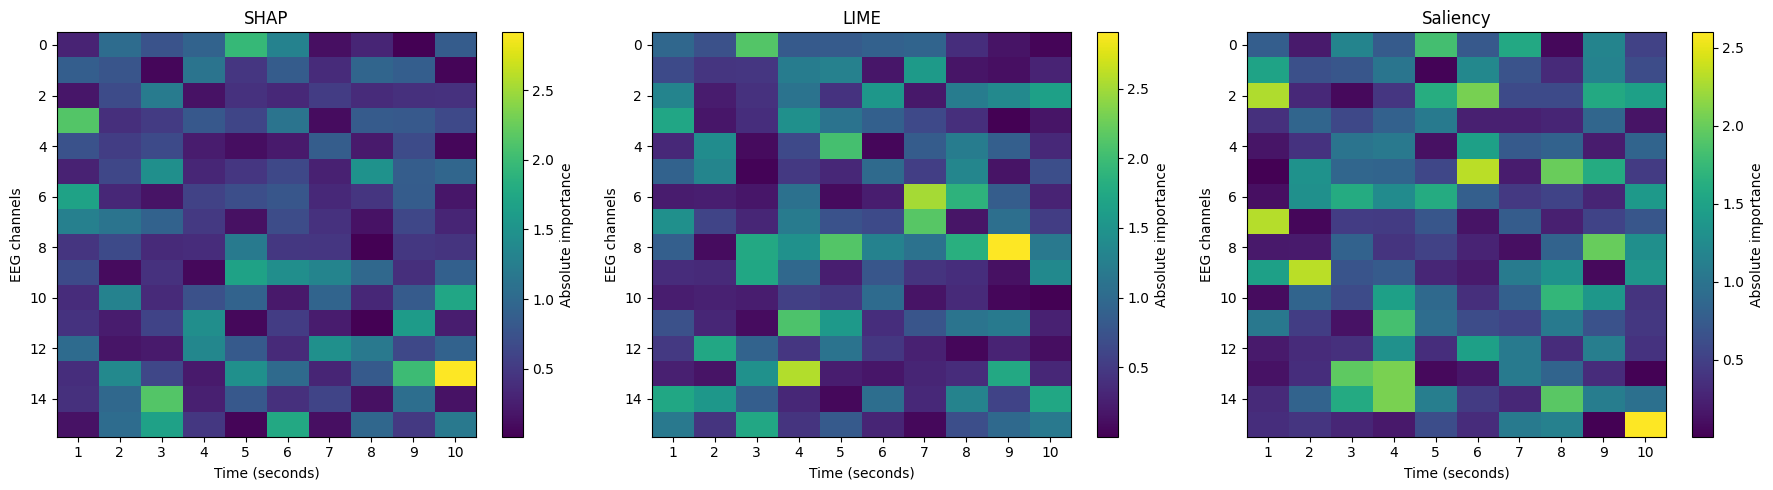

In [10]:
# Données artificielles pour tester l'affichage
rng = np.random.default_rng(42)

shap_test = rng.normal(size=(16, 10))
lime_test = rng.normal(size=(16, 10))
saliency_test = rng.normal(size=(16, 10))

compare_xai(shap_test, lime_test, saliency_test)

In [2]:

import os
import urllib.request

!pip -q install mne

import mne

os.makedirs("dataset/chb03", exist_ok=True)

url = "https://physionet.org/files/chbmit/1.0.0/chb03/chb03_01.edf"
path = "dataset/chb03/chb03_01.edf"

if not os.path.exists(path) or os.path.getsize(path) == 0:
    urllib.request.urlretrieve(url, path)

raw = mne.io.read_raw_edf(path, preload=False, verbose=False)

print("Nombre de canaux :", len(raw.ch_names))
print("Fréquence :", raw.info["sfreq"], "Hz")
print("Durée :", raw.times[-1], "secondes")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


/tmp/ipykernel_3048/33295486.py:16: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(path, preload=False, verbose=False)
/tmp/ipykernel_3048/33295486.py:16: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=False, verbose=False)


Nombre de canaux : 23
Fréquence : 256.0 Hz
Durée : 564.99609375 secondes


In [4]:

import numpy as np
from scipy.signal import butter, sosfiltfilt, resample_poly

channels = [
    "FP1-F7", "F7-T7", "T7-P7", "P7-O1",
    "FP1-F3", "F3-C3", "C3-P3", "P3-O1",
    "FP2-F4", "F4-C4", "C4-P4", "P4-O2",
    "FP2-F8", "F8-T8", "T8-P8", "P8-O2"
]

# Retirer les suffixes ajoutés par MNE aux canaux dupliqués
names = [name.upper().split("-")[0] if False else name.upper()
         for name in raw.ch_names]
names = [name.rsplit("-", 1)[0] if name.endswith(("-0", "-1")) else name
         for name in names]

indices = [names.index(ch) for ch in channels]

# MNE retourne des volts : conversion en microvolts
signal = raw.get_data(picks=indices) * 1e6

fs = int(raw.info["sfreq"])
sos = butter(4, (0.5, 75), btype="band", fs=fs, output="sos")
signal = sosfiltfilt(sos, signal, axis=1)
signal = resample_poly(signal, 200, fs, axis=1)

# Une fenêtre de 10 secondes
x = (signal[:, :2000] / 100).astype(np.float32)
x = x.reshape(16, 10, 200)

print("Forme :", x.shape)
print("Valeurs finies :", np.isfinite(x).all())


Forme : (16, 10, 200)
Valeurs finies : True


In [5]:

!git clone -q https://github.com/abhinandanvnayak/seizure-xai.git

import os

print("Dépôt téléchargé :", os.path.exists("seizure-xai"))
print("Fichiers disponibles :", os.listdir("seizure-xai"))


Dépôt téléchargé : True
Fichiers disponibles : ['third_party', 'results_cbramod.json', '.git', 'requirements.txt', 'scripts', 'results_zeroshot.json', '.gitignore', 'models', 'rtds', 'README.md']


In [6]:

import os

files = {
    "Poids CBraMod": "seizure-xai/third_party/cbramod/pretrained_weights.pth",
    "Classifieur chb03": "seizure-xai/models/cbramod/chb03.joblib",
    "Architecture CBraMod": "seizure-xai/third_party/cbramod/models/cbramod.py",
}

for name, path in files.items():
    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024**2)
        print(f"✅ {name} : présent ({size:.1f} Mo)")
    else:
        print(f"❌ {name} : absent")


❌ Poids CBraMod : absent
✅ Classifieur chb03 : présent (0.0 Mo)
✅ Architecture CBraMod : présent (0.0 Mo)


In [7]:

import os
import shutil

source = "/content/pretrained_weights.pth"
destination = "/content/seizure-xai/third_party/cbramod/pretrained_weights.pth"

os.makedirs(os.path.dirname(destination), exist_ok=True)

if os.path.isfile(source):
    shutil.move(source, destination)
    print("✅ Poids CBraMod installés")
    print("Taille :", round(os.path.getsize(destination) / 1024**2, 1), "Mo")
else:
    print("❌ Fichier introuvable : vérifie son importation dans Colab")


❌ Fichier introuvable : vérifie son importation dans Colab


In [8]:

import os

for dossier, sous_dossiers, fichiers in os.walk("/content"):
    for fichier in fichiers:
        if fichier == "pretrained_weights.pth":
            print("✅ Trouvé :", os.path.join(dossier, fichier))


In [12]:

import os
import shutil

source = "/content/pretrained_weights.pth"
destination = "/content/seizure-xai/third_party/cbramod/pretrained_weights.pth"

os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copy2(source, destination)

print("✅ Poids CBraMod installés !")
print("Taille :", round(os.path.getsize(destination) / 1024**2, 1), "Mo")


✅ Poids CBraMod installés !
Taille : 18.9 Mo


In [13]:

import sys
import torch

sys.path.insert(0, "/content/seizure-xai/third_party/cbramod")

from models.cbramod import CBraMod

device = "cuda" if torch.cuda.is_available() else "cpu"

model = CBraMod(
    in_dim=200,
    out_dim=200,
    d_model=200,
    dim_feedforward=800,
    seq_len=30,
    n_layer=12,
    nhead=8
)

weights_path = "/content/seizure-xai/third_party/cbramod/pretrained_weights.pth"

model.load_state_dict(torch.load(weights_path, map_location="cpu"))
model = model.to(device).eval()

print("✅ CBraMod chargé avec succès !")
print("Appareil utilisé :", device)


✅ CBraMod chargé avec succès !
Appareil utilisé : cpu


In [14]:

import numpy as np
import torch

# x contient notre vraie fenêtre EEG : (16, 10, 200)
eeg = torch.tensor(x, dtype=torch.float32).unsqueeze(0).to(device)

with torch.no_grad():
    h = model.encoder(model.patch_embedding(eeg))
    embedding = h.mean(dim=(1, 2)).cpu().numpy()

print("Fenêtre EEG :", tuple(eeg.shape))
print("Embedding CBraMod :", embedding.shape)
print("Valeurs finies :", np.isfinite(embedding).all())


Fenêtre EEG : (1, 16, 10, 200)
Embedding CBraMod : (1, 200)
Valeurs finies : True


In [15]:

import joblib
import numpy as np

# Charger le classifieur entraîné par Nayak
path = "/content/seizure-xai/models/cbramod/chb03.joblib"
saved = joblib.load(path)

# Récupérer le modèle et sa normalisation
clf = saved["clf"]
mu = saved["mu"]
sd = saved["sd"]

# Normaliser les caractéristiques CBraMod
embedding_norm = (embedding - mu) / sd

# Calculer le score
score = clf.decision_function(embedding_norm)[0]

print("✅ Score calculé !")
print("Score CBraMod + Logistic Regression :", round(float(score), 4))
print("Seuil enregistré :", saved["threshold"])


✅ Score calculé !
Score CBraMod + Logistic Regression : -0.2455
Seuil enregistré : -0.16763722833245992


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [16]:

import torch
import numpy as np

# Coefficients du classifieur de Nayak
coef = torch.tensor(
    clf.coef_[0], dtype=torch.float32, device=device
)
intercept = torch.tensor(
    clf.intercept_[0], dtype=torch.float32, device=device
)
mu_t = torch.tensor(mu, dtype=torch.float32, device=device)
sd_t = torch.tensor(sd, dtype=torch.float32, device=device)

# Fenêtre EEG avec calcul des gradients activé
eeg_grad = torch.tensor(
    x, dtype=torch.float32, device=device
).unsqueeze(0).requires_grad_(True)

# Passage dans CBraMod
h = model.encoder(model.patch_embedding(eeg_grad))
features = h.mean(dim=(1, 2))

# Score différentiable de la régression logistique
score_t = ((features - mu_t) / sd_t) @ coef + intercept

# Calcul des gradients
model.zero_grad()
score_t.sum().backward()

saliency = eeg_grad.grad.detach().abs().cpu().numpy()[0]

print("Score PyTorch :", round(score_t.item(), 4))
print("Score sklearn :", round(float(score), 4))
print("Saliency shape :", saliency.shape)
print("Valeurs finies :", np.isfinite(saliency).all())


Score PyTorch : -0.2455
Score sklearn : -0.2455
Saliency shape : (16, 10, 200)
Valeurs finies : True


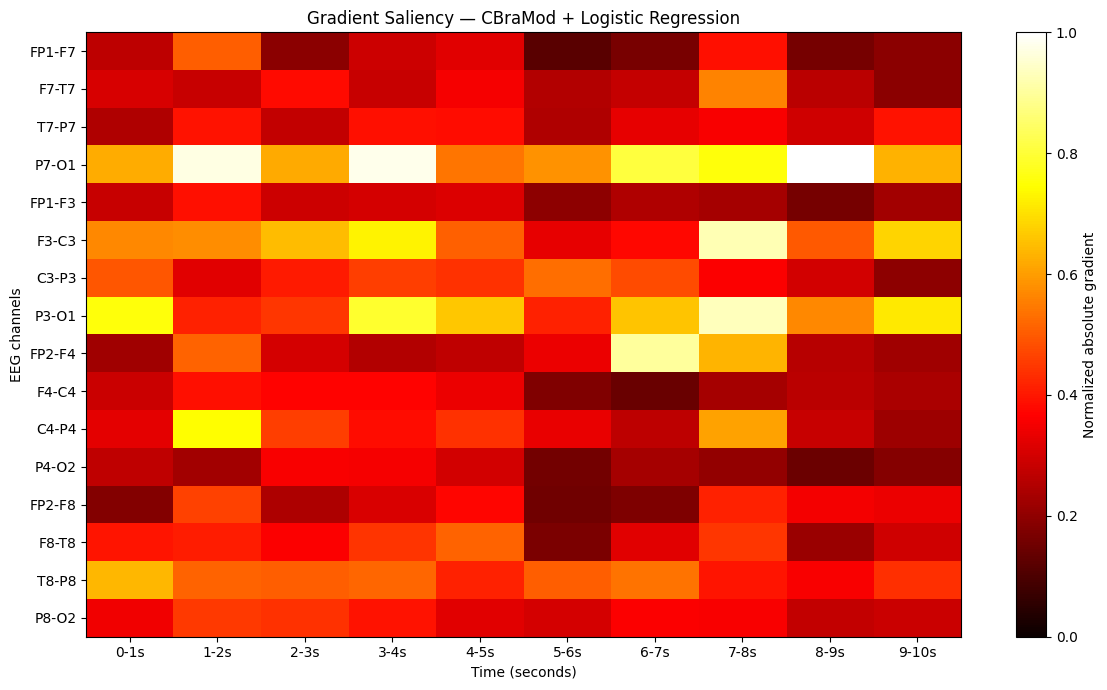

Canal le plus sensible : P7-O1
Seconde la plus sensible : 7


In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Moyenne des gradients absolus sur les 200 échantillons
# de chaque seconde
saliency_map = saliency.mean(axis=2)

# Normalisation pour faciliter la visualisation
saliency_norm = saliency_map / (saliency_map.max() + 1e-12)

plt.figure(figsize=(12, 7))

plt.imshow(
    saliency_norm,
    aspect="auto",
    cmap="hot",
    origin="upper",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Normalized absolute gradient")
plt.xticks(range(10), [f"{i}-{i+1}s" for i in range(10)])
plt.yticks(range(16), channels)

plt.xlabel("Time (seconds)")
plt.ylabel("EEG channels")
plt.title("Gradient Saliency — CBraMod + Logistic Regression")

plt.tight_layout()
plt.show()

print("Canal le plus sensible :", channels[saliency_map.mean(axis=1).argmax()])
print("Seconde la plus sensible :", saliency_map.mean(axis=0).argmax())


In [18]:

# Importance de chaque région canal-seconde
importance = saliency_map.flatten()

# Sélectionner les 10 % les plus importants
k = int(np.ceil(0.10 * importance.size))
top_indices = np.argsort(importance)[-k:]

# Copier l'EEG et masquer ces régions
x_masked = x.copy().reshape(160, 200)
x_masked[top_indices, :] = 0
x_masked = x_masked.reshape(16, 10, 200)

# Recalculer le score
with torch.no_grad():
    eeg_masked = torch.tensor(
        x_masked, dtype=torch.float32, device=device
    ).unsqueeze(0)

    h_masked = model.encoder(model.patch_embedding(eeg_masked))
    features_masked = h_masked.mean(dim=(1, 2)).cpu().numpy()

features_masked_norm = (features_masked - mu) / sd
score_masked = clf.decision_function(features_masked_norm)[0]

print("Score original :", round(float(score), 4))
print("Score après masquage :", round(float(score_masked), 4))
print("Variation absolue :", round(abs(float(score - score_masked)), 4))
print("Régions masquées :", k, "/ 160")


Score original : -0.2455
Score après masquage : -1.3204
Variation absolue : 1.0749
Régions masquées : 16 / 160


In [19]:

rng = np.random.default_rng(42)
random_drops = []

for i in range(20):
    # Choisir 16 régions aléatoires
    random_indices = rng.choice(160, size=k, replace=False)

    x_random = x.copy().reshape(160, 200)
    x_random[random_indices, :] = 0
    x_random = x_random.reshape(16, 10, 200)

    # Calculer le score du même modèle
    with torch.no_grad():
        eeg_random = torch.tensor(
            x_random, dtype=torch.float32, device=device
        ).unsqueeze(0)

        h_random = model.encoder(model.patch_embedding(eeg_random))
        features_random = h_random.mean(dim=(1, 2)).cpu().numpy()

    features_random_norm = (features_random - mu) / sd
    random_score = clf.decision_function(features_random_norm)[0]

    random_drops.append(float(score - random_score))

saliency_drop = float(score - score_masked)

print("Baisse du score avec Saliency :", round(saliency_drop, 4))
print("Baisse moyenne avec masquage aléatoire :", round(np.mean(random_drops), 4))
print("Écart-type aléatoire :", round(np.std(random_drops), 4))
print("Saliency supérieure à l'aléatoire :", saliency_drop > np.mean(random_drops))


Baisse du score avec Saliency : 1.0749
Baisse moyenne avec masquage aléatoire : 1.6954
Écart-type aléatoire : 0.4949
Saliency supérieure à l'aléatoire : False


In [20]:

import numpy as np
import torch

rng = np.random.default_rng(42)

# Ajouter un bruit faible : 1 % de l'écart-type du signal
noise_std = 0.01 * np.std(x)
x_noisy = x + rng.normal(
    0, noise_std, size=x.shape
).astype(np.float32)

# Recalculer les gradients sur le signal perturbé
eeg_noisy = torch.tensor(
    x_noisy, dtype=torch.float32, device=device
).unsqueeze(0).requires_grad_(True)

h_noisy = model.encoder(model.patch_embedding(eeg_noisy))
features_noisy = h_noisy.mean(dim=(1, 2))

score_noisy = ((features_noisy - mu_t) / sd_t) @ coef + intercept

model.zero_grad()
score_noisy.sum().backward()

saliency_noisy = eeg_noisy.grad.detach().abs().cpu().numpy()[0]
saliency_noisy_map = saliency_noisy.mean(axis=2)

# Comparer les deux heatmaps
correlation = np.corrcoef(
    saliency_map.flatten(),
    saliency_noisy_map.flatten()
)[0, 1]

print("Score original :", round(float(score), 4))
print("Score avec bruit :", round(float(score_noisy.item()), 4))
print("Corrélation Saliency :", round(float(correlation), 4))


Score original : -0.2455
Score avec bruit : -0.2266
Corrélation Saliency : 0.9722


In [21]:

import importlib.util

if importlib.util.find_spec("shap") is None:
    %pip install -q shap

import shap

print("✅ SHAP disponible")
print("Version SHAP :", shap.__version__)


✅ SHAP disponible
Version SHAP : 0.54.1


In [22]:

import numpy as np
import torch

# Notre fenêtre EEG de référence
x_reference = x.copy().reshape(160, 200)

def predict_shap(masks):
    masks = np.asarray(masks, dtype=np.float32)

    if masks.ndim == 1:
        masks = masks[None, :]

    scores = []

    # Traiter les masques par petits lots
    for start in range(0, len(masks), 4):
        batch_masks = masks[start:start + 4]

        # Conserver les régions sélectionnées,
        # masquer les autres avec des zéros
        eeg_batch = (
            batch_masks[:, :, None] * x_reference[None, :, :]
        ).reshape(-1, 16, 10, 200)

        eeg_tensor = torch.tensor(
            eeg_batch, dtype=torch.float32, device=device
        )

        with torch.no_grad():
            h = model.encoder(model.patch_embedding(eeg_tensor))
            features = h.mean(dim=(1, 2)).cpu().numpy()

        features_norm = (features - mu) / sd
        batch_scores = clf.decision_function(features_norm)
        scores.extend(batch_scores)

    return np.asarray(scores)

# Vérifier que le masque complet retrouve le score original
test_score = predict_shap(np.ones((1, 160)))[0]

print("Score original :", round(float(score), 4))
print("Score SHAP (sans masquage) :", round(float(test_score), 4))
print("Différence :", round(abs(float(score - test_score)), 6))


Score original : -0.2455
Score SHAP (sans masquage) : -0.2455
Différence : 0.0


In [23]:

import shap
import numpy as np
import time

# Référence : toutes les régions masquées
background = np.zeros((1, 160), dtype=np.float32)

# Fenêtre à expliquer : toutes les régions présentes
sample = np.ones((1, 160), dtype=np.float32)

# Créer l'explainer
explainer = shap.KernelExplainer(predict_shap, background)

print("Calcul SHAP en cours...")
start = time.time()

# Première estimation avec 200 évaluations
shap_values = explainer.shap_values(
    sample,
    nsamples=200,
    silent=True
)

shap_map = np.asarray(shap_values).reshape(16, 10)

print("✅ SHAP calculé !")
print("Durée :", round(time.time() - start, 1), "secondes")
print("Forme SHAP :", shap_map.shape)
print("Valeurs finies :", np.isfinite(shap_map).all())


Calcul SHAP en cours...
✅ SHAP calculé !
Durée : 10.2 secondes
Forme SHAP : (16, 10)
Valeurs finies : True


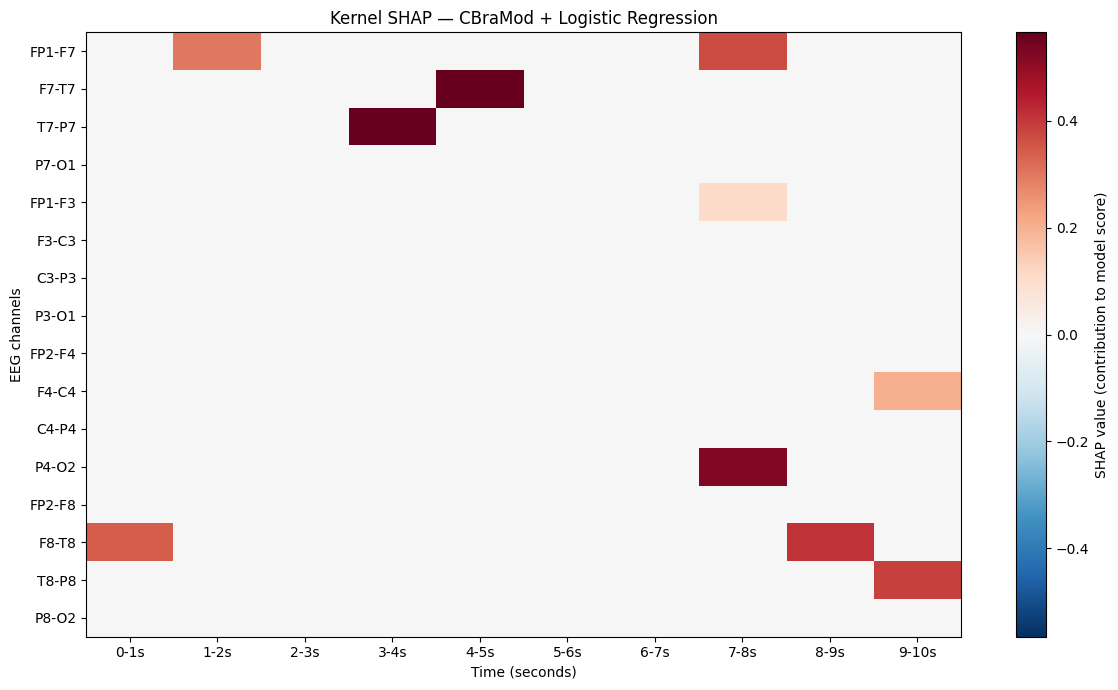

Canal le plus important : F8-T8
Seconde la plus importante : 7


In [24]:

import matplotlib.pyplot as plt
import numpy as np

# Échelle symétrique pour les contributions positives et négatives
vmax = np.max(np.abs(shap_map))

plt.figure(figsize=(12, 7))

plt.imshow(
    shap_map,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax
)

plt.colorbar(label="SHAP value (contribution to model score)")
plt.xticks(range(10), [f"{i}-{i+1}s" for i in range(10)])
plt.yticks(range(16), channels)

plt.xlabel("Time (seconds)")
plt.ylabel("EEG channels")
plt.title("Kernel SHAP — CBraMod + Logistic Regression")

plt.tight_layout()
plt.show()

# Importance absolue moyenne par canal et par seconde
shap_importance = np.abs(shap_map)

print("Canal le plus important :",
      channels[shap_importance.mean(axis=1).argmax()])

print("Seconde la plus importante :",
      int(shap_importance.mean(axis=0).argmax()))


In [26]:

import os

model_dir = "/content/seizure-xai/models/cbramod"

patients = [f"chb{i:02d}" for i in range(1, 17)]

print("MODÈLES DISPONIBLES\n")

for patient in patients:
    path = os.path.join(model_dir, patient + ".joblib")
    status = "✅" if os.path.isfile(path) else "❌"
    print(status, patient)

print(
    "\nNombre de modèles :",
    sum(
        os.path.isfile(os.path.join(model_dir, p + ".joblib"))
        for p in patients
    ),
    "/ 16"
)


MODÈLES DISPONIBLES

✅ chb01
❌ chb02
✅ chb03
✅ chb04
✅ chb05
✅ chb06
✅ chb07
✅ chb08
✅ chb09
✅ chb10
✅ chb11
❌ chb12
❌ chb13
✅ chb14
✅ chb15
❌ chb16

Nombre de modèles : 12 / 16


In [27]:

import os
import glob

model_dir = "/content/seizure-xai/models/cbramod"

files = sorted(glob.glob(os.path.join(model_dir, "*.joblib")))

print("Patients avec un modèle CBraMod :\n")

for f in files:
    print(os.path.basename(f).replace(".joblib", ""))

print("\nNombre total de modèles :", len(files))


Patients avec un modèle CBraMod :

chb01
chb03
chb04
chb05
chb06
chb07
chb08
chb09
chb10
chb11
chb14
chb15
chb17
chb19
chb20
chb22

Nombre total de modèles : 16


In [28]:

import os
import glob

repo = "/content/seizure-xai"

print("Fichier des résultats :")
print(os.path.exists(f"{repo}/results_cbramod.json"))

print("\nCaches d'embeddings :")
caches = glob.glob(f"{repo}/cache/*_cbramod.npz")
print("Nombre :", len(caches))

print("\nPatients présents dans les caches :")
for f in sorted(caches):
    print(os.path.basename(f).replace("_cbramod.npz", ""))



Fichier des résultats :
True

Caches d'embeddings :
Nombre : 0

Patients présents dans les caches :


In [29]:

import glob
import os

repo = "/content/seizure-xai"

files = glob.glob(
    f"{repo}/**/*cbramod*.npz",
    recursive=True
)

print("Fichiers trouvés :", len(files))

for f in sorted(files):
    print(os.path.relpath(f, repo))



Fichiers trouvés : 0


In [30]:

import sys

sys.path.insert(0, "/content/seizure-xai")

from rtds.config import Protocol

p = Protocol()

print("Paramètres du protocole :")
print("SPH :", p.sph, "secondes")
print("SOP :", p.sop, "secondes")
print("\nAttributs disponibles :")
print(vars(p))


Paramètres du protocole :
SPH : 300 secondes
SOP : 1800 secondes

Attributs disponibles :
{'sph': 300, 'sop': 1800, 'postictal': 7200, 'cluster_gap': 14400, 'train_frac': 0.5, 'target_fah': 0.5, 'smooth_steps': 5}


In [31]:

import json

path = "/content/seizure-xai/results_cbramod.json"

with open(path, "r") as f:
    results = json.load(f)

print("Nombre de patients :", len(results))
print("\nPatients :")

for patient in sorted(results):
    print(patient, "|", list(results[patient].keys()))


Nombre de patients : 16

Patients :
chb01 | ['n_seizures', 'hits', 'sensitivity', 'false_alarms', 'interictal_hours', 'fah', 'random_sensitivity', 'p_value', 'threshold', 'seizures', 'alarms', 'train_end']
chb03 | ['n_seizures', 'hits', 'sensitivity', 'false_alarms', 'interictal_hours', 'fah', 'random_sensitivity', 'p_value', 'threshold', 'seizures', 'alarms', 'train_end']
chb04 | ['n_seizures', 'hits', 'sensitivity', 'false_alarms', 'interictal_hours', 'fah', 'random_sensitivity', 'p_value', 'threshold', 'seizures', 'alarms', 'train_end']
chb05 | ['n_seizures', 'hits', 'sensitivity', 'false_alarms', 'interictal_hours', 'fah', 'random_sensitivity', 'p_value', 'threshold', 'seizures', 'alarms', 'train_end']
chb06 | ['n_seizures', 'hits', 'sensitivity', 'false_alarms', 'interictal_hours', 'fah', 'random_sensitivity', 'p_value', 'threshold', 'seizures', 'alarms', 'train_end']
chb07 | ['n_seizures', 'hits', 'sensitivity', 'false_alarms', 'interictal_hours', 'fah', 'random_sensitivity', 'p_

In [32]:

import json
from pprint import pprint

with open("/content/seizure-xai/results_cbramod.json") as f:
    results = json.load(f)

print("Exemple : patient chb01")
print("\nNombre de crises :", results["chb01"]["n_seizures"])
print("\nInformations sur les crises :")

pprint(results["chb01"]["seizures"][:3])



Exemple : patient chb01

Nombre de crises : 1

Informations sur les crises :
[{'detected': False, 'end': 91451.0, 'first_alarm': None, 'onset': 91350.0}]


In [33]:

total = 0
detected = 0

print("Patient | Crises de test | Détectées")

for patient in sorted(results):
    seizures = results[patient]["seizures"]
    n = len(seizures)
    hits = sum(s["detected"] for s in seizures)

    total += n
    detected += hits

    print(f"{patient:6} | {n:14} | {hits}")

print("\nTOTAL :", total, "crises")
print("Détectées :", detected)
print("Manquées :", total - detected)


Patient | Crises de test | Détectées
chb01  |              1 | 0
chb03  |              1 | 1
chb04  |              1 | 0
chb05  |              1 | 1
chb06  |              3 | 1
chb07  |              1 | 0
chb08  |              1 | 1
chb09  |              1 | 0
chb10  |              3 | 2
chb11  |              1 | 1
chb14  |              2 | 2
chb15  |              2 | 1
chb17  |              1 | 1
chb19  |              1 | 1
chb20  |              1 | 0
chb22  |              1 | 0

TOTAL : 22 crises
Détectées : 12
Manquées : 10


In [34]:

import os
import glob

folders = [
    "/content/dataset",
    "/content/seizure-xai/data/raw"
]

for folder in folders:
    files = sorted(glob.glob(
        os.path.join(folder, "**", "*.edf"),
        recursive=True
    ))

    print(f"\nDossier : {folder}")
    print("Nombre de fichiers EEG :", len(files))

    for file in files[:20]:
        print(" ", os.path.relpath(file, folder))



Dossier : /content/dataset
Nombre de fichiers EEG : 1
  chb03/chb03_01.edf

Dossier : /content/seizure-xai/data/raw
Nombre de fichiers EEG : 0


In [35]:

import requests
from pathlib import Path

patient = "chb01"
url = (
    "https://physionet.org/files/chbmit/1.0.0/"
    f"{patient}/{patient}-summary.txt"
)

folder = Path("/content/dataset") / patient
folder.mkdir(parents=True, exist_ok=True)

response = requests.get(url, timeout=30)
response.raise_for_status()

path = folder / f"{patient}-summary.txt"
path.write_bytes(response.content)

print("Fichier téléchargé :", path)
print("Taille :", path.stat().st_size, "octets")
print("\nDébut du fichier :")
print(path.read_text()[:700])


Fichier téléchargé : /content/dataset/chb01/chb01-summary.txt
Taille : 5355 octets

Début du fichier :
Data Sampling Rate: 256 Hz
*************************

Channels in EDF Files:
**********************
Channel 1: FP1-F7
Channel 2: F7-T7
Channel 3: T7-P7
Channel 4: P7-O1
Channel 5: FP1-F3
Channel 6: F3-C3
Channel 7: C3-P3
Channel 8: P3-O1
Channel 9: FP2-F4
Channel 10: F4-C4
Channel 11: C4-P4
Channel 12: P4-O2
Channel 13: FP2-F8
Channel 14: F8-T8
Channel 15: T8-P8
Channel 16: P8-O2
Channel 17: FZ-CZ
Channel 18: CZ-PZ
Channel 19: P7-T7
Channel 20: T7-FT9
Channel 21: FT9-FT10
Channel 22: FT10-T8
Channel 23: T8-P8

File Name: chb01_01.edf
File Start Time: 11:42:54
File End Time: 12:42:54
Number of Seizures in File: 0

File Name: chb01_02.edf
File Start Time: 12:42:57
File End Time: 13:42:57
Numbe


In [36]:

import requests
from pathlib import Path

patients = sorted(results.keys())
base = "https://physionet.org/files/chbmit/1.0.0"
root = Path("/content/dataset")

for patient in patients:
    folder = root / patient
    folder.mkdir(parents=True, exist_ok=True)

    path = folder / f"{patient}-summary.txt"

    if not path.exists():
        url = f"{base}/{patient}/{patient}-summary.txt"
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        path.write_bytes(response.content)

    print("✅", patient, "-", path.stat().st_size, "octets")

print("\nTotal :", len(patients), "résumés disponibles")


✅ chb01 - 5355 octets
✅ chb03 - 4935 octets
✅ chb04 - 5645 octets
✅ chb05 - 4911 octets
✅ chb06 - 3083 octets
✅ chb07 - 2711 octets
✅ chb08 - 2946 octets
✅ chb09 - 3245 octets
✅ chb10 - 3605 octets
✅ chb11 - 4900 octets
✅ chb14 - 3849 octets
✅ chb15 - 6890 octets
✅ chb17 - 3417 octets
✅ chb19 - 4334 octets
✅ chb20 - 4160 octets
✅ chb22 - 4028 octets

Total : 16 résumés disponibles


In [39]:

import os

path = "/content/dataset/chb01/chb01_25.edf"

if os.path.isfile(path):
    print("✅ Fichier téléchargé :", round(os.path.getsize(path)/1e6, 1), "Mo")
else:
    print("❌ Fichier absent")


✅ Fichier téléchargé : 4.2 Mo


In [40]:

import mne

path = "/content/dataset/chb01/chb01_25.edf"

try:
    raw = mne.io.read_raw_edf(path, preload=False, verbose=False)
    print("✅ EDF valide")
    print("Durée :", round(raw.times[-1] / 60, 1), "minutes")
    print("Canaux :", len(raw.ch_names))
except Exception as e:
    print("❌ EDF incomplet ou invalide :", str(e)[:200])


✅ EDF valide
Durée : 5.9 minutes
Canaux : 23


/tmp/ipykernel_3048/1034724474.py:6: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(path, preload=False, verbose=False)
/tmp/ipykernel_3048/1034724474.py:6: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(path, preload=False, verbose=False)


In [42]:

import subprocess, time

subprocess.run(
    ["pip", "-q", "install", "awscli"],
    check=True
)

source = "s3://physionet-open/chbmit/1.0.0/chb01/chb01_25.edf"
destination = "/content/dataset/chb01/chb01_25.edf"

start = time.time()

try:
    subprocess.run(
        ["aws", "s3", "cp", source, destination,
         "--no-sign-request", "--only-show-errors"],
        check=True,
        timeout=120
    )
    print("✅ Téléchargement terminé en",
          round(time.time()-start), "secondes")
except subprocess.TimeoutExpired:
    print("⏹️ Téléchargement arrêté après 2 minutes")
except subprocess.CalledProcessError:
    print("❌ Téléchargement AWS échoué")


✅ Téléchargement terminé en 3 secondes


Device: cpu

========== chb01 ==========
Downloading: chb01 chb01_26.edf


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


chb01_91350 Saliency | faithfulness: -2.033 | robustness: 0.891
chb01_91350 SHAP | faithfulness: 0.353 | robustness: 0.867
chb01_91350 LIME | faithfulness: 0.291 | robustness: 0.964

========== chb03 ==========
Downloading: chb03 chb03_34.edf


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


chb03_306049 Saliency | faithfulness: 1.162 | robustness: 0.952
chb03_306049 SHAP | faithfulness: 0.466 | robustness: 0.915
chb03_306049 LIME | faithfulness: 0.94 | robustness: 0.964

========== chb04 ==========
Downloading: chb04 chb04_28.edf


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


... (23 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


chb20_234792 Saliency | faithfulness: -0.26 | robustness: 0.83
chb20_234792 SHAP | faithfulness: 1.327 | robustness: 0.879
chb20_234792 LIME | faithfulness: 0.789 | robustness: 0.952

========== chb22 ==========
Downloading: chb22 chb22_38.edf


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


chb22_135003 Saliency | faithfulness: -1.353 | robustness: 0.988
chb22_135003 SHAP | faithfulness: 0.544 | robustness: 0.842
chb22_135003 LIME | faithfulness: 1.535 | robustness: 0.915


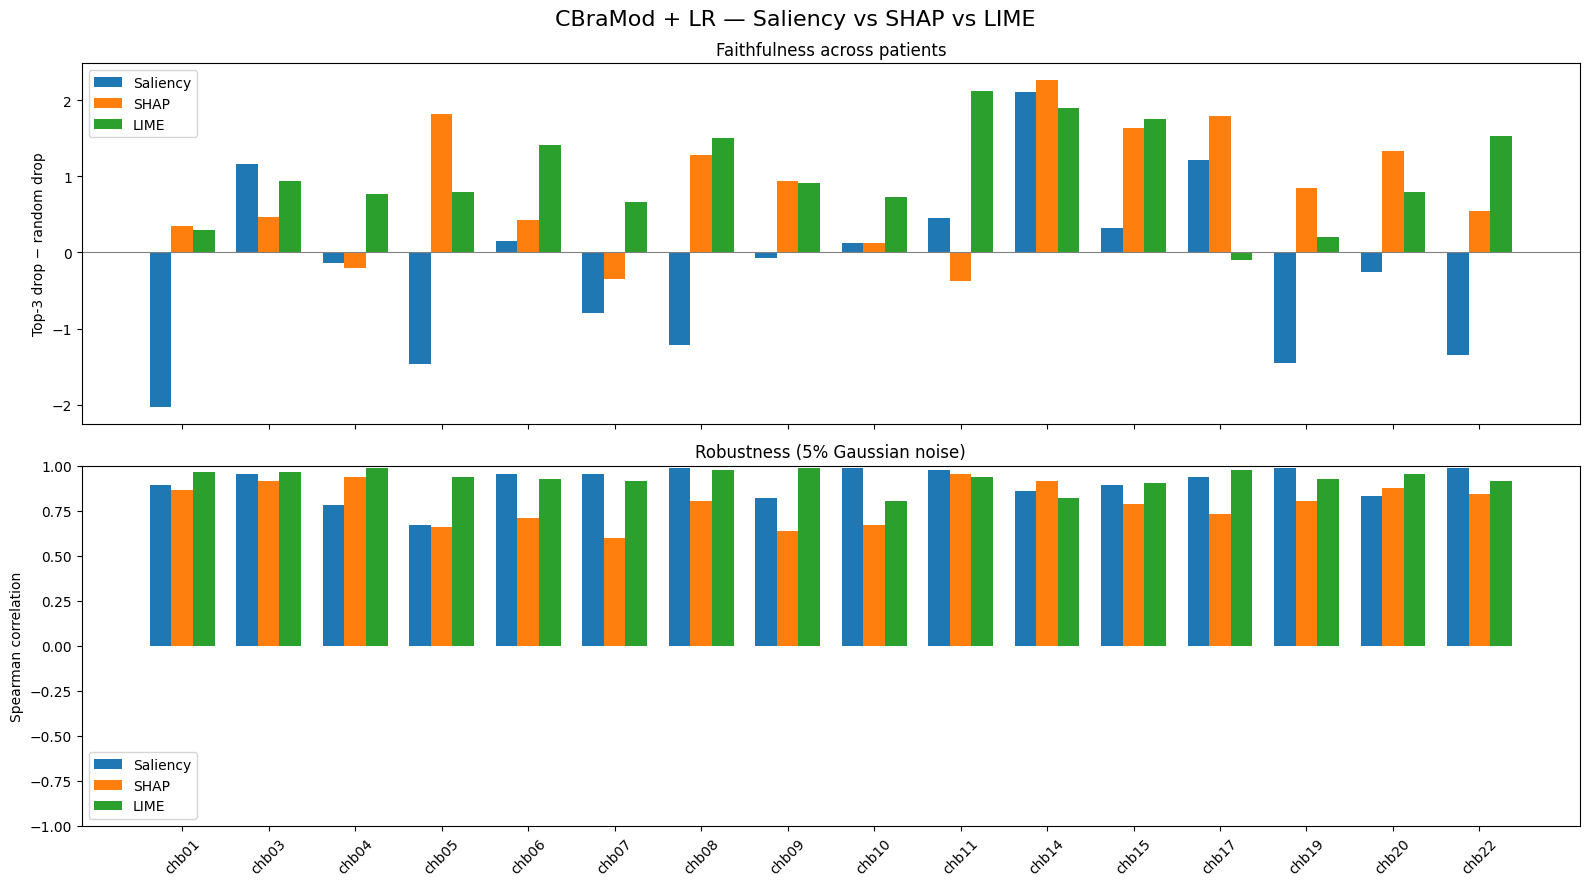


========== FINISHED ==========
Patients: 16 / 16
Seizures: 22 / 22
CSV: /content/xai_comparison/xai_results.csv
Figure: /content/xai_comparison/comparison_16_patients.png


In [43]:

# ============================================================
# CBraMod + LR — 16 PATIENTS — SALIENCY / SHAP / LIME
# AWS S3 + FAITHFULNESS + ROBUSTNESS + FIGURE
# ============================================================

import os, sys, json, subprocess, warnings, gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import joblib
import requests
import mne
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.signal import butter, sosfiltfilt, resample_poly

subprocess.run(
    [sys.executable, "-m", "pip", "-q", "install",
     "shap", "lime", "awscli"],
    check=True
)

import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore", category=RuntimeWarning)

REPO = Path("/content/seizure-xai")
DATA = Path("/content/dataset")
OUT = Path("/content/xai_comparison")
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "third_party/cbramod"))

from rtds.chb import parse_summary
from models.cbramod import CBraMod

with open(REPO / "results_cbramod.json") as f:
    results = json.load(f)

PATIENTS = [
    "chb01", "chb03", "chb04", "chb05",
    "chb06", "chb07", "chb08", "chb09",
    "chb10", "chb11", "chb14", "chb15",
    "chb17", "chb19", "chb20", "chb22"
]

CHANNELS = [
    "FP1-F7", "F7-T7", "T7-P7", "P7-O1",
    "FP1-F3", "F3-C3", "C3-P3", "P3-O1",
    "FP2-F4", "F4-C4", "C4-P4", "P4-O2",
    "FP2-F8", "F8-T8", "T8-P8", "P8-O2"
]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, flush=True)

model = CBraMod(
    in_dim=200, out_dim=200, d_model=200,
    dim_feedforward=800, seq_len=30,
    n_layer=12, nhead=8
)

model.load_state_dict(
    torch.load(
        REPO / "third_party/cbramod/pretrained_weights.pth",
        map_location="cpu",
        weights_only=False
    )
)
model = model.to(DEVICE).eval()

# Evaluation settings
TOP_K = 3
N_RANDOM = 5
NOISE_LEVEL = 0.05
SHAP_SAMPLES = 128
LIME_SAMPLES = 200
rng = np.random.default_rng(42)

# ------------------------------------------------------------
# 1. AWS DOWNLOAD
# ------------------------------------------------------------

def get_edf(patient, filename, required_end):
    folder = DATA / patient
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / filename

    if path.exists():
        try:
            raw = mne.io.read_raw_edf(
                str(path), preload=False, verbose=False
            )
            duration = raw.n_times / raw.info["sfreq"]
            if duration >= required_end:
                return path
        except Exception:
            pass

    source = (
        f"s3://physionet-open/chbmit/1.0.0/"
        f"{patient}/{filename}"
    )
    tmp = Path(str(path) + ".part")
    tmp.unlink(missing_ok=True)

    print("Downloading:", patient, filename, flush=True)

    subprocess.run(
        [
            "aws", "s3", "cp",
            source, str(tmp),
            "--no-sign-request",
            "--only-show-errors"
        ],
        check=True,
        timeout=180
    )

    os.replace(tmp, path)
    return path

# ------------------------------------------------------------
# 2. LOAD 10-SECOND EEG WINDOW
# ------------------------------------------------------------

def load_eeg_window(path, local_end):
    raw = mne.io.read_raw_edf(
        str(path), preload=False, verbose=False
    )

    # MNE may rename duplicate channels using suffixes
    names = [n.upper() for n in raw.ch_names]

    indices = []
    for ch in CHANNELS:
        matches = [
            i for i, n in enumerate(names)
            if n == ch or n.startswith(ch + "-")
        ]
        if not matches:
            raise ValueError(f"Missing channel: {ch}")
        indices.append(matches[0])

    fs = int(raw.info["sfreq"])
    end = int(round(local_end * fs))
    start = end - 10 * fs

    if start < 0 or end > raw.n_times:
        raise ValueError("Window outside EDF duration")

    margin = 5 * fs
    a = max(0, start-margin)
    b = min(raw.n_times, end+margin)

    eeg = raw.get_data(
        picks=indices, start=a, stop=b
    ) * 1e6

    sos = butter(
        4, [0.5, min(75, fs/2-1)],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    eeg = sosfiltfilt(sos, eeg, axis=1)
    eeg = eeg[:, start-a:end-a]

    eeg = resample_poly(eeg, 200, fs, axis=1)

    if eeg.shape != (16, 2000):
        raise ValueError(f"Wrong EEG shape: {eeg.shape}")

    # Scale for pretrained CBraMod
    eeg = (eeg / 100).astype(np.float32)
    return eeg.reshape(16, 10, 200)

# ------------------------------------------------------------
# 3. MODEL PREDICTION
# ------------------------------------------------------------

def get_embedding(batch, with_grad=False):
    x = torch.as_tensor(
        batch, dtype=torch.float32, device=DEVICE
    )

    if with_grad:
        h = model.encoder(model.patch_embedding(x))
        return h.mean(dim=(1, 2))

    with torch.no_grad():
        h = model.encoder(model.patch_embedding(x))
        return h.mean(dim=(1, 2)).cpu().numpy()

def model_score(batch, clf, mu, sd):
    emb = get_embedding(batch)
    return np.asarray(
        clf.decision_function((emb-mu)/sd)
    ).reshape(-1)

def mask_windows(window, masks):
    masks = np.asarray(masks, dtype=np.float32).reshape(-1, 10)
    return window[None] * masks[:, None, :, None]

# ------------------------------------------------------------
# 4. THREE EXPLANATION METHODS
# ------------------------------------------------------------

def explain_saliency(window, clf, mu, sd):
    x = torch.tensor(
        window[None],
        dtype=torch.float32,
        device=DEVICE,
        requires_grad=True
    )

    coef = torch.tensor(
        clf.coef_[0], dtype=torch.float32, device=DEVICE
    )
    intercept = torch.tensor(
        clf.intercept_[0], dtype=torch.float32, device=DEVICE
    )
    mt = torch.tensor(mu, dtype=torch.float32, device=DEVICE)
    st = torch.tensor(sd, dtype=torch.float32, device=DEVICE)

    model.zero_grad()
    emb = get_embedding(x, with_grad=True)
    score = ((emb-mt)/st) @ coef + intercept
    score.sum().backward()

    return (
        x.grad.detach().abs()
        .mean(dim=(0, 1, 3))
        .cpu().numpy()
    )

def explain_shap(window, predict):
    explainer = shap.KernelExplainer(
        predict,
        np.zeros((1, 10))
    )
    values = explainer.shap_values(
        np.ones((1, 10)),
        nsamples=SHAP_SAMPLES,
        silent=True
    )
    return np.asarray(values).reshape(-1)[:10]

def explain_lime(window, predict):
    background = rng.integers(
        0, 2, size=(200, 10)
    ).astype(float)

    explainer = LimeTabularExplainer(
        background,
        mode="regression",
        feature_names=[f"second_{i}" for i in range(10)],
        discretize_continuous=False,
        random_state=42
    )

    exp = explainer.explain_instance(
        np.ones(10),
        lambda masks: predict(np.clip(masks, 0, 1)),
        num_features=10,
        num_samples=LIME_SAMPLES
    )

    importance = np.zeros(10)
    for idx, value in exp.local_exp[1]:
        importance[idx] = value

    return importance

# ------------------------------------------------------------
# 5. FAITHFULNESS + ROBUSTNESS
# ------------------------------------------------------------

def evaluate(window, importance, predict, method,
             clf, mu, sd):

    baseline = predict(np.ones((1, 10)))[0]

    top = np.argsort(importance)[-TOP_K:]
    top_mask = np.ones((1, 10))
    top_mask[0, top] = 0

    top_drop = baseline - predict(top_mask)[0]

    random_masks = np.ones((N_RANDOM, 10))
    for i in range(N_RANDOM):
        selected = rng.choice(10, TOP_K, replace=False)
        random_masks[i, selected] = 0

    random_drop = baseline - predict(random_masks).mean()

    # Perturb input with Gaussian noise
    noisy = (
        window +
        rng.normal(
            0,
            NOISE_LEVEL * max(float(window.std()), 1e-8),
            window.shape
        )
    ).astype(np.float32)

    def noisy_predict(masks):
        return model_score(
            mask_windows(noisy, masks), clf, mu, sd
        )

    if method == "Saliency":
        noisy_importance = explain_saliency(
            noisy, clf, mu, sd
        )
    elif method == "SHAP":
        noisy_importance = explain_shap(
            noisy, noisy_predict
        )
    else:
        noisy_importance = explain_lime(
            noisy, noisy_predict
        )

    rho = spearmanr(
        importance, noisy_importance
    ).correlation

    return (
        float(top_drop),
        float(random_drop),
        float(rho)
    )

# ------------------------------------------------------------
# 6. PROCESS ALL 16 PATIENTS
# ------------------------------------------------------------

for patient in PATIENTS:
    print(f"\n========== {patient} ==========", flush=True)

    try:
        bundle = joblib.load(
            REPO / "models/cbramod" / f"{patient}.joblib"
        )
        clf = bundle["clf"]
        mu = bundle["mu"]
        sd = bundle["sd"]

        summary_path = (
            DATA / patient / f"{patient}-summary.txt"
        )

        if not summary_path.exists():
            summary_path.parent.mkdir(
                parents=True, exist_ok=True
            )
            url = (
                "https://physionet.org/files/chbmit/1.0.0/"
                f"{patient}/{patient}-summary.txt"
            )
            response = requests.get(url, timeout=30)
            response.raise_for_status()
            summary_path.write_bytes(response.content)

        records = parse_summary(summary_path)

        for seizure in results[patient]["seizures"]:
            onset = float(seizure["onset"])
            tag = f"{patient}_{int(onset)}"
            output_file = OUT / f"{tag}.json"

            if output_file.exists():
                print("Already done:", tag, flush=True)
                continue

            try:
                # Window ending 20 minutes before seizure
                target = onset - 1200

                record = next(
                    r for r in records
                    if r.start <= target-10
                    and r.end >= target
                )

                local_end = target - record.start

                path = get_edf(
                    patient, record.name, local_end
                )

                window = load_eeg_window(
                    path, local_end
                )

                def predict(masks):
                    return model_score(
                        mask_windows(window, masks),
                        clf, mu, sd
                    )

                explanations = {
                    "Saliency": explain_saliency(
                        window, clf, mu, sd
                    ),
                    "SHAP": explain_shap(
                        window, predict
                    ),
                    "LIME": explain_lime(
                        window, predict
                    )
                }

                seizure_rows = []

                for method, importance in explanations.items():
                    top, random_drop, rho = evaluate(
                        window, importance, predict,
                        method, clf, mu, sd
                    )

                    seizure_rows.append({
                        "patient": patient,
                        "onset": onset,
                        "method": method,
                        "top_drop": top,
                        "random_drop": random_drop,
                        "faithfulness_gap": top-random_drop,
                        "robustness": rho
                    })

                    print(
                        tag, method,
                        "| faithfulness:",
                        round(top-random_drop, 3),
                        "| robustness:",
                        round(rho, 3),
                        flush=True
                    )

                output_file.write_text(
                    json.dumps(seizure_rows, indent=2)
                )

            except Exception as e:
                print("ERROR", tag, repr(e), flush=True)

    except Exception as e:
        print("PATIENT ERROR", patient, repr(e), flush=True)

    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 7. SAVE RESULTS AND CREATE COMPARATIVE FIGURE
# ------------------------------------------------------------

rows = []

for path in sorted(OUT.glob("chb*.json")):
    rows.extend(json.loads(path.read_text()))

if not rows:
    raise RuntimeError(
        "No results generated. Check errors printed above."
    )

df = pd.DataFrame(rows)
df.to_csv(OUT / "xai_results.csv", index=False)

agg = (
    df.groupby(["patient", "method"], as_index=False)
    .agg(
        faithfulness=("faithfulness_gap", "mean"),
        robustness=("robustness", "median")
    )
)

methods = ["Saliency", "SHAP", "LIME"]
fig, axes = plt.subplots(
    2, 1, figsize=(16, 9), sharex=True
)

x = np.arange(len(PATIENTS))
width = 0.25

for i, method in enumerate(methods):
    sub = (
        agg[agg["method"] == method]
        .set_index("patient")
        .reindex(PATIENTS)
    )

    offset = (i-1)*width

    axes[0].bar(
        x+offset,
        sub["faithfulness"],
        width,
        label=method
    )
    axes[1].bar(
        x+offset,
        sub["robustness"],
        width,
        label=method
    )

axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_ylabel("Top-3 drop − random drop")
axes[0].set_title("Faithfulness across patients")
axes[0].legend()

axes[1].set_ylabel("Spearman correlation")
axes[1].set_title("Robustness (5% Gaussian noise)")
axes[1].set_ylim(-1, 1)
axes[1].set_xticks(x)
axes[1].set_xticklabels(PATIENTS, rotation=45)
axes[1].legend()

fig.suptitle(
    "CBraMod + LR — Saliency vs SHAP vs LIME",
    fontsize=16
)
fig.tight_layout()

fig.savefig(
    OUT / "comparison_16_patients.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

completed = df[["patient", "onset"]].drop_duplicates()

print("\n========== FINISHED ==========")
print("Patients:", df.patient.nunique(), "/ 16")
print("Seizures:", len(completed), "/ 22")
print("CSV:", OUT / "xai_results.csv")
print("Figure:", OUT / "comparison_16_patients.png")


In [44]:

import pandas as pd

df = pd.read_csv("/content/xai_comparison/xai_results.csv")

summary = df.groupby("method").agg(
    faithfulness_mean=("faithfulness_gap", "mean"),
    faithfulness_std=("faithfulness_gap", "std"),
    faithfulness_median=("faithfulness_gap", "median"),
    robustness_mean=("robustness", "mean"),
    robustness_std=("robustness", "std"),
    robustness_median=("robustness", "median")
).round(3)

display(summary)


,faithfulness_mean,faithfulness_std,faithfulness_median,robustness_mean,robustness_std,robustness_median
method,,,,,,
LIME,1.096,0.839,1.300,0.915,0.075,0.927
SHAP,0.814,0.953,0.890,0.779,0.136,0.818
Saliency,-0.013,1.174,-0.018,0.897,0.106,0.933


In [45]:

from pathlib import Path
import shutil

folder = Path("/content/XAI_Comparison_Mannel")
folder.mkdir(exist_ok=True)

# Results and figure
source = Path("/content/xai_comparison")

for filename in ["xai_results.csv", "comparison_16_patients.png"]:
    file = source / filename
    if file.exists():
        shutil.copy2(file, folder / filename)

# Individual seizure results
results_folder = folder / "individual_results"
results_folder.mkdir(exist_ok=True)

for file in source.glob("chb*.json"):
    shutil.copy2(file, results_folder / file.name)

# Save the notebook as a .ipynb separately using
# Colab: File > Download > Download .ipynb
print("Files prepared:", [p.name for p in folder.iterdir()])

# Create ZIP
zip_path = shutil.make_archive(
    "/content/XAI_Comparison_Mannel",
    "zip",
    root_dir="/content",
    base_dir="XAI_Comparison_Mannel"
)

print("ZIP created:", zip_path)

from google.colab import files
files.download(zip_path)


Files prepared: ['comparison_16_patients.png', 'xai_results.csv', 'individual_results']
ZIP created: /content/XAI_Comparison_Mannel.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:

import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

df = pd.read_csv("/content/xai_comparison/xai_results.csv")

comparisons = [
    ("faithfulness_gap", "LIME", "Saliency"),
    ("faithfulness_gap", "SHAP", "Saliency"),
    ("robustness", "SHAP", "LIME")
]

rows = []

for metric, method1, method2 in comparisons:
    paired = df.pivot_table(
        index=["patient", "onset"],
        columns="method",
        values=metric
    )[[method1, method2]].dropna()

    stat, p = wilcoxon(
        paired[method1],
        paired[method2]
    )

    rows.append({
        "Metric": metric,
        "Comparison": f"{method1} vs {method2}",
        "N": len(paired),
        "p_raw": p
    })

results_stats = pd.DataFrame(rows)

results_stats["p_holm"] = multipletests(
    results_stats["p_raw"],
    method="holm"
)[1]

display(results_stats.round(5))

results_stats.to_csv(
    "/content/xai_comparison/statistical_tests.csv",
    index=False
)


,Metric,Comparison,N,p_raw,p_holm
0,faithfulness_gap,LIME vs Saliency,22,0.00036,0.00072
1,faithfulness_gap,SHAP vs Saliency,22,0.00832,0.00832
2,robustness,SHAP vs LIME,22,0.00018,0.00053


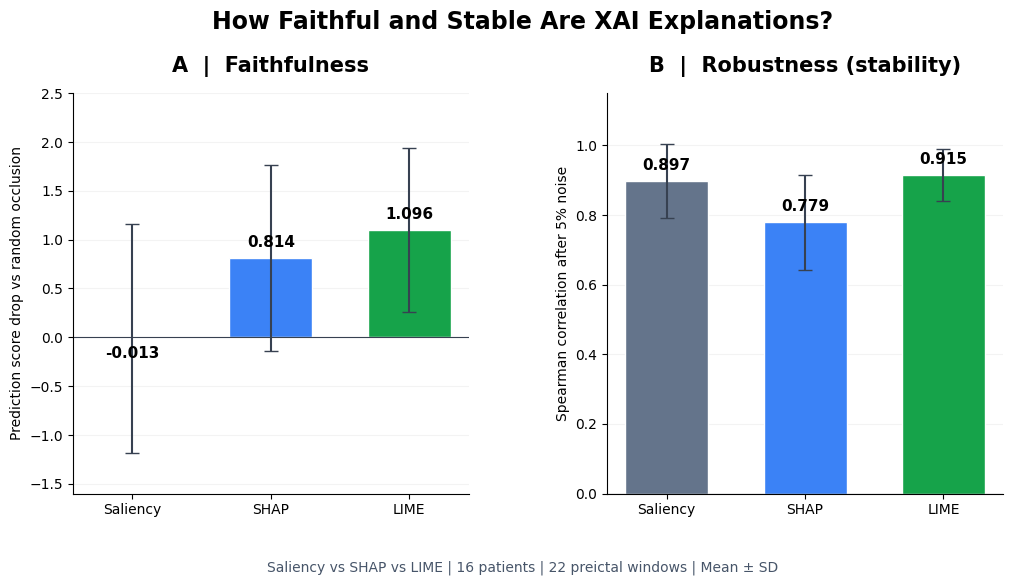

Figures saved successfully!


In [47]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load existing results
output_dir = Path("/content/xai_comparison")
df = pd.read_csv(output_dir / "xai_results.csv")

# Compute means and standard deviations
methods = ["Saliency", "SHAP", "LIME"]
metrics = ["faithfulness_gap", "robustness"]

summary = (
    df.groupby("method")[metrics]
    .agg(["mean", "std"])
    .reindex(methods)
)

colors = {
    "Saliency": "#64748B",
    "SHAP": "#3B82F6",
    "LIME": "#16A34A"
}

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5.2),
    gridspec_kw={"wspace": 0.35}
)

settings = [
    ("faithfulness_gap", "A  |  Faithfulness",
     "Prediction score drop vs random occlusion"),
    ("robustness", "B  |  Robustness (stability)",
     "Spearman correlation after 5% noise")
]

for ax, (metric, title, ylabel) in zip(axes, settings):
    means = summary[(metric, "mean")].values
    stds = summary[(metric, "std")].values

    bars = ax.bar(
        methods, means,
        color=[colors[m] for m in methods],
        width=0.6,
        edgecolor="white"
    )

    ax.errorbar(
        range(len(methods)), means,
        yerr=stds,
        fmt="none",
        ecolor="#374151",
        elinewidth=1.5,
        capsize=5
    )

    ax.axhline(0, color="#374151", linewidth=0.8)
    ax.set_title(title, fontsize=15, weight="bold", pad=15)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    for bar, value in zip(bars, means):
        ax.annotate(
            f"{value:.3f}",
            (bar.get_x() + bar.get_width()/2, value),
            xytext=(0, 8 if value >= 0 else -14),
            textcoords="offset points",
            ha="center",
            fontsize=11,
            weight="bold"
        )

    if metric == "robustness":
        ax.set_ylim(0, 1.15)
    else:
        ax.set_ylim(-1.6, 2.5)

fig.suptitle(
    "How Faithful and Stable Are XAI Explanations?",
    fontsize=17, fontweight="bold", y=1.04
)

fig.text(
    0.5, -0.04,
    "Saliency vs SHAP vs LIME | 16 patients | "
    "22 preictal windows | Mean ± SD",
    ha="center", fontsize=10, color="#475569"
)

plt.savefig(
    output_dir / "poster_xai_comparison.png",
    dpi=300, bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    output_dir / "poster_xai_comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figures saved successfully!")


In [48]:

from google.colab import files

files.download(
    "/content/xai_comparison/poster_xai_comparison.png"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>